In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten

In [2]:
X_train = np.loadtxt("input.csv", delimiter=",")
Y_train = np.loadtxt("labels.csv", delimiter=",")
X_test = np.loadtxt("input_test.csv", delimiter=",")
Y_test = np.loadtxt("labels_test.csv", delimiter=",")

print("Data loaded successfully.")

Data loaded successfully.


In [3]:
X_train = X_train.reshape(-1, 100, 100, 3).astype("float32") / 255.0
X_test = X_test.reshape(-1, 100, 100, 3).astype("float32") / 255.0

Y_train = Y_train.reshape(-1, 1)
Y_test = Y_test.reshape(-1, 1)

In [4]:
print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)
print("X_test:", X_test.shape)
print("Y_test:", Y_test.shape)

X_train: (2000, 100, 100, 3)
Y_train: (2000, 1)
X_test: (400, 100, 100, 3)
Y_test: (400, 1)


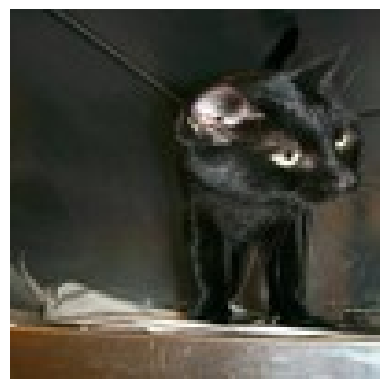

Label: 1.0


In [5]:
idx = random.randrange(len(X_train))
plt.imshow(X_train[idx])
plt.axis("off")
plt.show()

print("Label:", Y_train[idx].item())

In [6]:
model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(100, 100, 3)),
    MaxPooling2D((2, 2)),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(64, activation="relu"),
    Dense(1, activation="sigmoid")
])

C:\Users\Dell\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 98, 98, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 49, 49, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 47, 47, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 23, 23, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 16928)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │       1,083,456 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,093,665 (4.17 MB)

 Trainable params: 1,093,665 (4.17 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

In [9]:
history = model.fit(
    X_train,
    Y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 9s 185ms/step - accuracy: 0.5931 - loss: 0.7293 - val_accuracy: 0.0000e+00 - val_loss: 0.9339
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 161ms/step - accuracy: 0.6250 - loss: 0.6512 - val_accuracy: 0.0000e+00 - val_loss: 1.1447
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 159ms/step - accuracy: 0.6463 - loss: 0.6187 - val_accuracy: 0.1850 - val_loss: 0.8547
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 161ms/step - accuracy: 0.6950 - loss: 0.5743 - val_accuracy: 0.1425 - val_loss: 1.1268
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 145ms/step - accuracy: 0.7356 - loss: 0.5331 - val_accuracy: 0.4950 - val_loss: 0.7948
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 160ms/step - accuracy: 0.7769 - loss: 0.4764 - val_accuracy: 0.5500 - val_loss: 0.7531
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 157ms/step - accuracy: 0.8000 - loss: 0.4293 - val_accuracy: 0.6350 - val_loss: 0.7025
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 157ms/step - accuracy: 0.8244 - loss: 0.3883 - val_accu

In [10]:
test_loss, test_accuracy = model.evaluate(X_test, Y_test, verbose=0)
print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

Test loss: 0.7110089659690857
Test accuracy: 0.6675000190734863


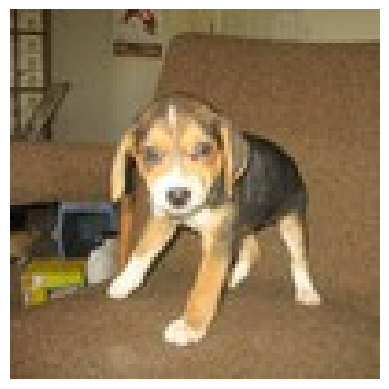

Predicted class: dog
Cat probability: 0.06595746
Actual label: 0.0


In [11]:
idx2 = random.randrange(len(X_test))

plt.imshow(X_test[idx2])
plt.axis("off")
plt.show()

probability = model.predict(X_test[idx2:idx2+1], verbose=0)[0, 0]

# This assumes label 0 = dog and label 1 = cat.
pred = "cat" if probability >= 0.5 else "dog"

print("Predicted class:", pred)
print("Cat probability:", probability)
print("Actual label:", Y_test[idx2].item())